<a href="https://colab.research.google.com/github/JiawenAi/MSSP6070/blob/main/Assignments/Assignment02/Assignment2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import userdata
import os
import subprocess
import pandas as pd
import matplotlib.pyplot as plt

github_token = userdata.get('Git_key')

owner = 'JiawenAi'
repository = 'MSSP6070'

clone_url = f'https://{github_token}@github.com/{owner}/{repository}.git'

subprocess.run(['git', 'clone', clone_url])

os.chdir(repository)

df = pd.read_csv(
    "data/InternetSales.csv",
    encoding="latin1",
    low_memory=False
)

In [2]:
print("Dataset shape:", df.shape)
display(df.head())
df.info()

Dataset shape: (60398, 60)


,ID,CustomerKey,GeographyKey,City,CountryRegionCode,EnglishCountryRegionName,CustomerAlternateKey,Title,FirstName,MiddleName,...,ProductStandardCost,TotalProductCost,SalesAmount,TaxAmt,Freight,CarrierTrackingNumber,CustomerPONumber,OrderDate,DueDate,ShipDate
0,0,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1912.1544,1912.1544,3399.99,271.9992,84.9998,NaN,NaN,1/19/2011,1/31/2011,1/26/2011
1,1,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1265.6195,1265.6195,2319.99,185.5992,57.9998,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
2,2,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,8.2205,8.2205,21.98,1.7584,0.5495,NaN,NaN,1/18/2013,1/30/2013,1/25/2013
3,3,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,1481.9379,1481.9379,2384.07,190.7256,59.6018,NaN,NaN,5/3/2013,5/15/2013,5/10/2013
4,4,11000,26,Rockhampton,AU,Australia,AW00011000,NaN,Jon,V,...,10.8423,10.8423,28.99,2.3192,0.7248,NaN,NaN,5/3/2013,5/15/2013,5/10/2013


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60398 entries, 0 to 60397
Data columns (total 60 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ID                        60398 non-null  int64  
 1   CustomerKey               60398 non-null  int64  
 2   GeographyKey              60398 non-null  int64  
 3   City                      60398 non-null  object 
 4   CountryRegionCode         60398 non-null  object 
 5   EnglishCountryRegionName  60398 non-null  object 
 6   CustomerAlternateKey      60398 non-null  object 
 7   Title                     307 non-null    object 
 8   FirstName                 60398 non-null  object 
 9   MiddleName                34903 non-null  object 
 10  LastName                  60398 non-null  object 
 11  NameStyle                 60398 non-null  bool   
 12  BirthDate                 60398 non-null  object 
 13  MaritalStatus             60398 non-null  object 
 14  Suffix

In [3]:
#filter the variables that actually matters in this analysis
key_columns = [
    'CustomerKey',
    'EnglishCountryRegionName',
    'OrderDate',
    'SalesOrderNumber',
    'SalesOrderLineNumber',
    'SalesAmount',
    'ProductKey',
    'EnglishProductName',
    'UnitPrice',
    'OrderQuantity',
    'YearlyIncome',
    'Gender',
    'HouseOwnerFlag'
]

#check missing values for those key factors
display(df[key_columns].isnull().sum())

,0
CustomerKey,0
EnglishCountryRegionName,0
OrderDate,0
SalesOrderNumber,0
SalesOrderLineNumber,0
SalesAmount,0
ProductKey,0
EnglishProductName,0
UnitPrice,0
OrderQuantity,0


In [4]:
#convert the date values to datetime form
df['OrderDate'] = pd.to_datetime(df['OrderDate'], errors='coerce')
#extract the "year" values
df['Year'] = df['OrderDate'].dt.year

#check date range
print("First order:", df['OrderDate'].min())
print("Last order:", df['OrderDate'].max())

#find the number of records by year
display(df.groupby('Year').size())

First order: 2010-12-29 00:00:00
Last order: 2014-01-28 00:00:00


,0
Year,
2010,14
2011,2216
2012,3397
2013,52801
2014,1970


In [5]:
#Internet Sales Analysis by Year and Country Region

#find the sales by country
sales_by_region = (
    df.groupby(['Year', 'EnglishCountryRegionName'])['SalesAmount']
    .sum()
    .unstack(fill_value=0)
)

display(sales_by_region.round(2))

EnglishCountryRegionName,Australia,Canada,France,Germany,United Kingdom,United States
Year,,,,,,
2010,20909.78,3578.27,3399.99,0.00,699.10,14833.90
2011,2563732.25,571571.80,410845.33,520500.16,550591.22,2458285.17
2012,2128407.46,307604.52,648065.54,608657.98,712700.96,1437048.73
2013,4339443.38,1085632.65,1578511.80,1761876.36,2124007.29,5462078.86
2014,8507.72,9457.62,3195.06,3277.83,3713.64,17542.85


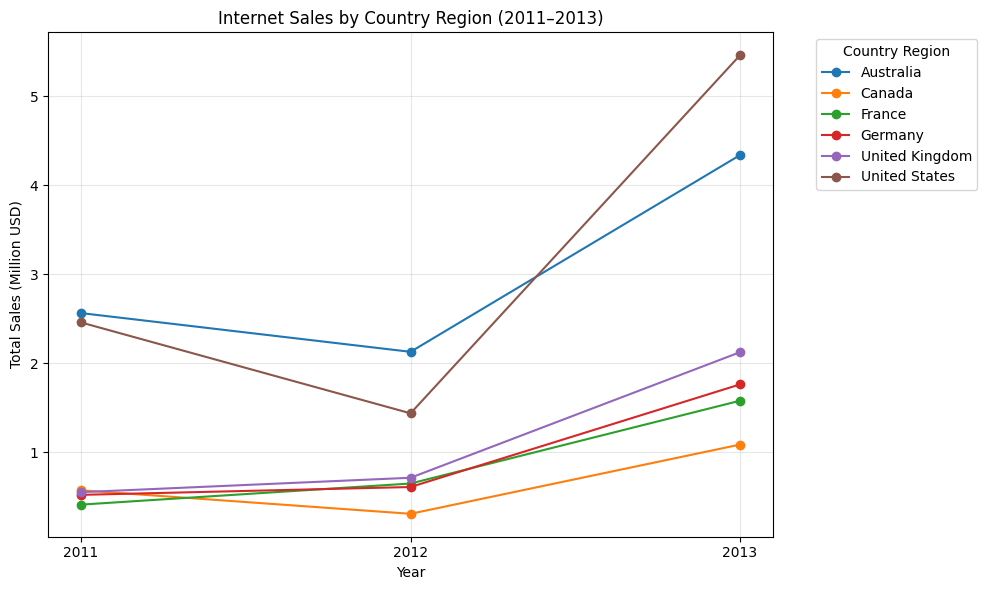

In [6]:
#plot the sales values by year (valid years only)

sales_full_years = sales_by_region.loc[2011:2013] / 1_000_000

sales_full_years.plot(
    kind='line',
    marker='o',
    figsize=(10, 6)
)

plt.title('Internet Sales by Country Region (2011–2013)')
plt.xlabel('Year')
plt.ylabel('Total Sales (Million USD)')
plt.xticks([2011, 2012, 2013])
plt.legend(title='Country Region', bbox_to_anchor=(1.05, 1))
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig('Figure1_RegionalSales.png',
            dpi=300, bbox_inches='tight')
plt.show()

In [7]:
#find annual sales and average sales per order

yearly_summary = df.groupby('Year').agg(
    TotalSales=('SalesAmount', 'sum'),
    Orders=('SalesOrderNumber', 'nunique')
)

yearly_summary['SalesPerOrder'] = (
    yearly_summary['TotalSales'] / yearly_summary['Orders']
)

display(yearly_summary.round(2))

,TotalSales,Orders,SalesPerOrder
Year,,,
2010,43421.04,14,3101.50
2011,7075525.93,2216,3192.93
2012,5842485.20,3269,1787.24
2013,16351550.34,21289,768.08
2014,45694.72,871,52.46


In [8]:
#create a dataset with one record per customer (costumer level data)
customers = df.drop_duplicates(subset='CustomerKey').copy()

print("Unique customers:", len(customers))

#checking on the data
display(customers[
    ['CustomerKey', 'EnglishCountryRegionName',
     'YearlyIncome', 'Gender']
].head())

Unique customers: 18484


,CustomerKey,EnglishCountryRegionName,YearlyIncome,Gender
0,11000,Australia,90000,M
8,11001,Australia,60000,M
19,11002,Australia,60000,M
23,11003,Australia,70000,F
32,11004,Australia,80000,F


In [9]:
# Summary statistics for yearly income by country region

income_summary = (
    customers.groupby('EnglishCountryRegionName')['YearlyIncome']
    .agg(['count', 'mean', 'min', 'max', 'std'])
)

display(income_summary.round(2))

,count,mean,min,max,std
EnglishCountryRegionName,,,,,
Australia,3591,64338.62,10000,170000,31830.00
Canada,1571,57167.41,10000,170000,20251.52
France,1810,35762.43,10000,110000,27277.40
Germany,1780,42943.82,10000,130000,35493.58
United Kingdom,1913,52169.37,10000,170000,48431.99
United States,7819,63616.83,10000,170000,25706.48


In [10]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [11]:
income_table = income_summary.rename(columns={
    'count': 'Customers',
    'mean': 'Mean ($)',
    'min': 'Min ($)',
    'max': 'Max ($)',
    'std': 'SD ($)'
})

income_table = income_table.round(0)

income_table.to_excel('Table1_IncomeSummary.xlsx')

In [12]:
#gender distribution analysis by country region

gender_summary = pd.crosstab(
    customers['EnglishCountryRegionName'],
    customers['Gender']
)

display(gender_summary)

#convert to percentage
gender_pct = gender_summary.div(
    gender_summary.sum(axis=1), axis=0
) * 100

display(gender_pct.round(2))

Gender,F,M
EnglishCountryRegionName,,
Australia,1777,1814
Canada,767,804
France,893,917
Germany,874,906
United Kingdom,934,979
United States,3888,3931


Gender,F,M
EnglishCountryRegionName,,
Australia,49.48,50.52
Canada,48.82,51.18
France,49.34,50.66
Germany,49.10,50.90
United Kingdom,48.82,51.18
United States,49.73,50.27


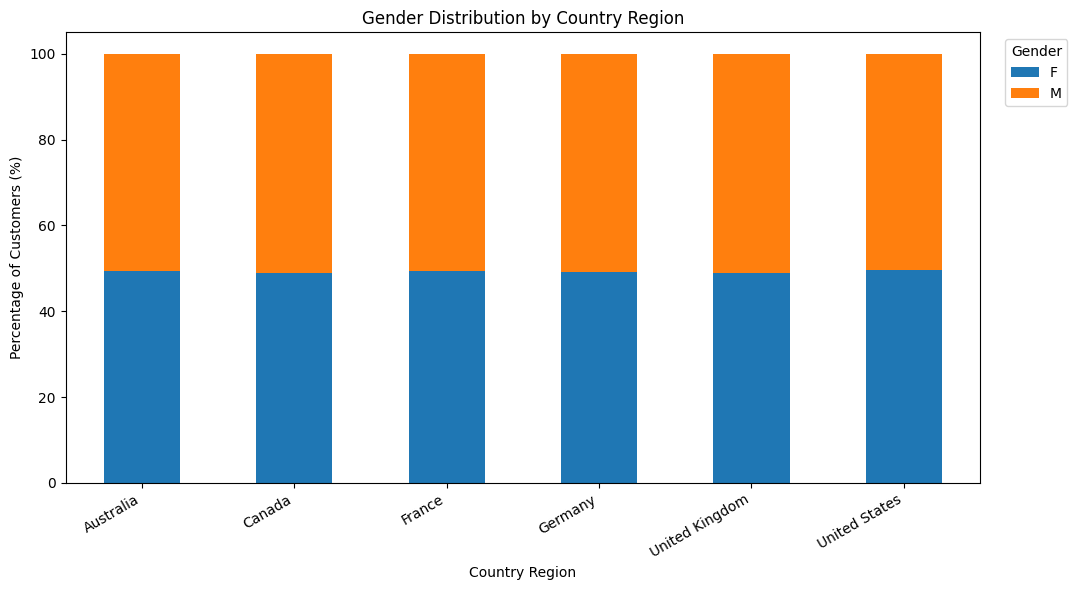

In [13]:
#graph of the gender distribution by country region
#show the composition

gender_pct.plot(
    kind='bar',
    stacked=True,
    figsize=(10, 6)
)

plt.title('Gender Distribution by Country Region')
plt.xlabel('Country Region')
plt.ylabel('Percentage of Customers (%)')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.legend(
    title='Gender',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)
plt.savefig('Figure2_GenderDistribution.png',
            dpi=300, bbox_inches='tight')

plt.show()

In [14]:
#analysis of the Product Category Sales and Average Price
display(
    df[['ProductKey', 'EnglishProductName']]
    .drop_duplicates()
    .sort_values('ProductKey')
    .head(30)
)

,ProductKey,EnglishProductName
6,214,"Sport-100 Helmet, Red"
18,217,"Sport-100 Helmet, Black"
22,222,"Sport-100 Helmet, Blue"
13,225,AWC Logo Cap
139,228,"Long-Sleeve Logo Jersey, S"
480,231,"Long-Sleeve Logo Jersey, M"
261,234,"Long-Sleeve Logo Jersey, L"
948,237,"Long-Sleeve Logo Jersey, XL"
559,310,"Road-150 Red, 62"
1868,311,"Road-150 Red, 44"


In [15]:
#classify products and calculate sales

#classify products by category
def classify_product(name):
    name = name.lower()

    if name.startswith(('road-', 'mountain-', 'touring-')):
        return 'Bikes'
    elif any(word in name for word in [
        'jersey', 'shorts', 'gloves', 'socks',
        'cap', 'vest', 'tights'
    ]):
        return 'Clothing'
    else:
        return 'Accessories'

df['ProductCategory'] = df['EnglishProductName'].apply(classify_product)


#total sales by category
category_sales = (
    df.groupby('ProductCategory')['SalesAmount']
    .sum()
    .sort_values(ascending=False)
)

display(category_sales.round(2))


,SalesAmount
ProductCategory,
Bikes,28318144.65
Accessories,700759.96
Clothing,339772.61


In [16]:
#identify the highest-sales category and its average price
top_category = category_sales.idxmax()

top_products = df[df['ProductCategory'] == top_category]

average_price = (
    (top_products['UnitPrice'] * top_products['OrderQuantity']).sum()
    / top_products['OrderQuantity'].sum()
)

print("Highest sales category:", top_category)
print("Total sales:", round(category_sales.max(), 2))
print("Average selling price:", round(average_price, 2))

Highest sales category: Bikes
Total sales: 28318144.65
Average selling price: 1862.42


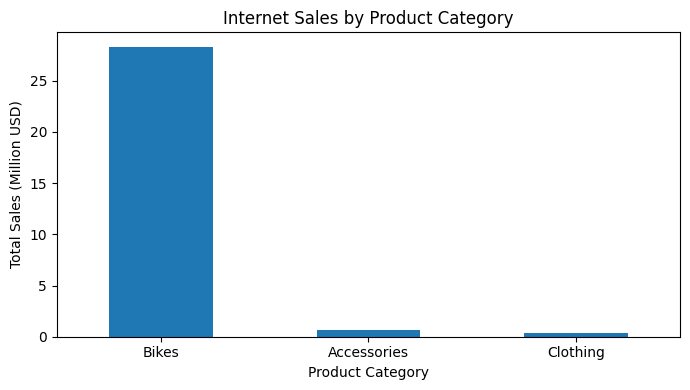

In [17]:
#figure for product category sales

(category_sales / 1_000_000).plot(
    kind='bar',
    figsize=(7, 4)
)

plt.title('Internet Sales by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Sales (Million USD)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('Figure3_ProductCategory.png',
            dpi=300, bbox_inches='tight')
plt.show()

In [18]:
# Sales by homeownership analysis
customer_sales = (
    df.groupby(['CustomerKey', 'HouseOwnerFlag'])['SalesAmount']
    .sum()
    .reset_index()
)

home_summary = (
    customer_sales.groupby('HouseOwnerFlag')['SalesAmount']
    .agg(['count', 'sum', 'mean', 'median'])
)

display(home_summary.round(2))

,count,sum,mean,median
HouseOwnerFlag,,,,
0,5982,8973327.42,1500.05,209.96
1,12502,20385349.80,1630.57,342.00


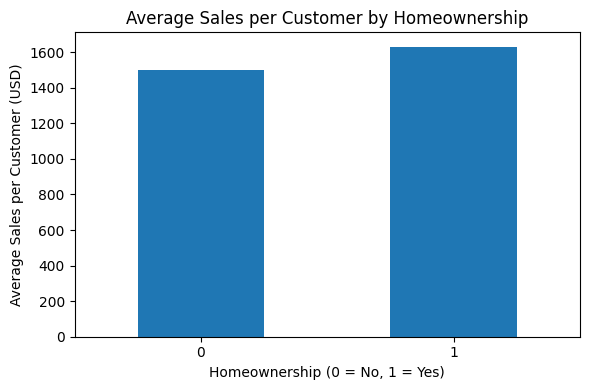

In [19]:
# figure for average sales per customer by homeownership plot

home_summary['mean'].plot(
    kind='bar',
    figsize=(6, 4)
)

plt.title('Average Sales per Customer by Homeownership')
plt.xlabel('Homeownership (0 = No, 1 = Yes)')
plt.ylabel('Average Sales per Customer (USD)')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('Figure4_Homeownership.png',
            dpi=300, bbox_inches='tight')
plt.show()